# Decision Tree classes and their scikit-learn methods


fit(self, X, y[, sample_weight, …])	Build a decision tree classifier from the training set (X, y).

get_depth(self)				Return the depth of the decision tree.

get_params(self[, deep])		Get parameters for this estimator.

predict(self, X[, check_input])Predict class or regression value for X.
	

score(self, X, y[, sample_weight])	Return the mean accuracy on the given test data and labels.

set_params(self, \*\*params)		Set the parameters of this estimator.

....

In [1]:
#load data set
from sklearn import neighbors, datasets
iris = datasets.load_iris()

x, y = iris.data, iris.target

print("Format x: ",type(x), x.shape)
print("Format y: ",type(y), y.shape)

Format x:  <class 'numpy.ndarray'> (150, 4)
Format y:  <class 'numpy.ndarray'> (150,)


In [2]:
#train test split
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.4, random_state=17)

In [3]:
# simple classification tree
from sklearn import tree

#initialize model
dt = tree.DecisionTreeClassifier()
#fit model to training data
dt.fit(x_train,y_train)
#predict label for a given data set
print("Predicted label for iris flower with feature values [3, 5, 4, 2]: ",iris.target_names[dt.predict([[3, 5, 4, 2]])])

Predicted label for iris flower with feature values [3, 5, 4, 2]:  ['virginica']


[Text(0.3333333333333333, 0.9166666666666666, 'x[3] <= 0.8\ngini = 0.657\nsamples = 90\nvalue = [35, 23, 32]'),
 Text(0.16666666666666666, 0.75, 'gini = 0.0\nsamples = 35\nvalue = [35, 0, 0]'),
 Text(0.5, 0.75, 'x[3] <= 1.65\ngini = 0.487\nsamples = 55\nvalue = [0, 23, 32]'),
 Text(0.3333333333333333, 0.5833333333333334, 'x[2] <= 4.95\ngini = 0.204\nsamples = 26\nvalue = [0, 23, 3]'),
 Text(0.16666666666666666, 0.4166666666666667, 'gini = 0.0\nsamples = 22\nvalue = [0, 22, 0]'),
 Text(0.5, 0.4166666666666667, 'x[1] <= 2.65\ngini = 0.375\nsamples = 4\nvalue = [0, 1, 3]'),
 Text(0.3333333333333333, 0.25, 'gini = 0.0\nsamples = 2\nvalue = [0, 0, 2]'),
 Text(0.6666666666666666, 0.25, 'x[2] <= 5.45\ngini = 0.5\nsamples = 2\nvalue = [0, 1, 1]'),
 Text(0.5, 0.08333333333333333, 'gini = 0.0\nsamples = 1\nvalue = [0, 1, 0]'),
 Text(0.8333333333333334, 0.08333333333333333, 'gini = 0.0\nsamples = 1\nvalue = [0, 0, 1]'),
 Text(0.6666666666666666, 0.5833333333333334, 'gini = 0.0\nsamples = 29\nvalu

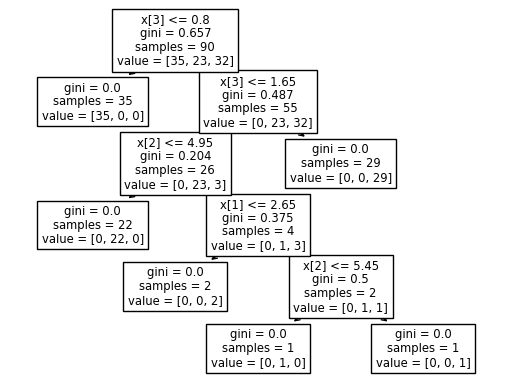

In [4]:
from sklearn import tree
tree.plot_tree(dt)

In [5]:
#Predict multiple values (e.g. predictions for entire test data set)
dt.predict(x_test)

array([0, 1, 2, 1, 2, 2, 1, 2, 1, 2, 2, 0, 1, 0, 2, 0, 0, 2, 2, 2, 1, 0,
       2, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 2, 1, 0, 1, 1, 0, 1,
       2, 1, 2, 2, 1, 0, 2, 1, 1, 2, 1, 0, 1, 2, 2, 0])

In [6]:
#calculate accuracy for test data
dt.score(x_test,y_test)

0.95

In [7]:
#Gradient Boosted Tree
from sklearn.ensemble import GradientBoostingClassifier

gbt = GradientBoostingClassifier(n_estimators=100, max_depth=4, learning_rate=1.0,random_state=0)
gbt.fit(x_train,y_train)

gbt.score(x_test,y_test)

0.9666666666666667

In [8]:
#Bagging Tree
from sklearn.ensemble import BaggingClassifier

bagt= BaggingClassifier(tree.DecisionTreeClassifier(),
                        n_estimators=10, random_state=0).fit(x_train,y_train)
bagt.score(x_test,y_test)

0.95